In [4]:
# Customer Segmentation

In [17]:
import pandas as pd
import numpy as np
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import plotly.express as px
import plotly.graph_objects as go
import matplotlib.pyplot as plt



In [18]:
scaled_data = pd.read_csv(
    'C:/Users/Mega-Pc/Freelance/data/ecommerce/data_cleaned+scaled.csv',
    encoding='ISO-8859-1'
)

real_data = pd.read_csv(
    'C:/Users/Mega-Pc/Freelance/data/ecommerce/data_before_scaling.csv',
    encoding='ISO-8859-1'
)

In [19]:
def aggregate_by_customer(df):
    return df.groupby('CustomerID').agg({
        'TotalSpent': 'sum',
        'NumTransactions': 'sum',
        'AvgTransactionValue': 'mean',
        'MaxTransactionValue': 'max',
        'TotalPrice': 'sum',
        'AvgPricePerItem': 'mean',
        'AvgUnitPriceSold': 'mean',
        'TotalQuantity': 'sum',
        'Quantity': 'sum',
        'AvgItemsPerTransaction': 'mean',
        'NumUniqueItemsBought': 'sum',
        'CustomerProductAffinity': 'mean',
        'RecencyDays': 'mean',
        'FrequencyPerMonth': 'mean',
        'MonetaryPerMonth': 'mean',
        'AvgDaysBetweenInvoices': 'mean',
        'TenureDays': 'mean',
        'TenureMonths': 'mean',
        'Recency_x_Frequency': 'mean',
        'Frequency_x_Monetary': 'mean',
        'ReturnRate': 'mean',
        'SentimentScore': 'mean',
        'AvgSentimentScore': 'mean',
        'IsDeluxe': 'mean',
        'InvoiceMonth': lambda x: x.mode()[0],
        'InvoiceQuarter': lambda x: x.mode()[0],
        'InvoiceDayOfWeek': lambda x: x.mode()[0],
        'InvoiceHour': lambda x: x.mode()[0],
        'IsWeekend': 'mean',
        'IsHolidaySeason': 'mean',
        'CountryAvgSpend': 'mean',
        'CountryAvgSpendDeviation': 'mean',
        'FirstPurchase_Year': 'min',
        'FirstPurchase_Month': 'min',
        'FirstPurchase_Day': 'min',
        'FirstPurchase_Hour': 'min',
        'LastPurchase_Year': 'max',
        'LastPurchase_Month': 'max',
        'LastPurchase_Day': 'max',
        'LastPurchase_Hour': 'max',
    }).reset_index()

scaled_data = aggregate_by_customer(scaled_data)
real_data = aggregate_by_customer(real_data)

In [20]:
features = [
    'TotalSpent', 'NumTransactions', 'AvgTransactionValue', 'MaxTransactionValue',
    'TotalQuantity', 'AvgItemsPerTransaction', 'NumUniqueItemsBought', 'CustomerProductAffinity',
    'RecencyDays', 'FrequencyPerMonth', 'MonetaryPerMonth', 'AvgDaysBetweenInvoices',
    'TenureDays', 'TenureMonths', 'Recency_x_Frequency', 'Frequency_x_Monetary',
    'ReturnRate', 'SentimentScore', 'AvgSentimentScore', 'IsDeluxe',
    'InvoiceMonth', 'InvoiceQuarter', 'InvoiceDayOfWeek', 'InvoiceHour',
    'IsWeekend', 'IsHolidaySeason', 'CountryAvgSpendDeviation'
]

X_scaled = scaled_data[features]


In [21]:
import hdbscan
clusterer = hdbscan.HDBSCAN(
    min_cluster_size=30,   # tu peux ajuster selon ton dataset
    min_samples=10,        # plus grand = plus robuste aux outliers
    metric='euclidean'
)

scaled_data['Cluster'] = clusterer.fit_predict(X_scaled)
real_data['Cluster'] = scaled_data['Cluster']

scaled_data['Cluster'].value_counts()


Cluster
-1    2448
 1    1852
 0      72
Name: count, dtype: int64

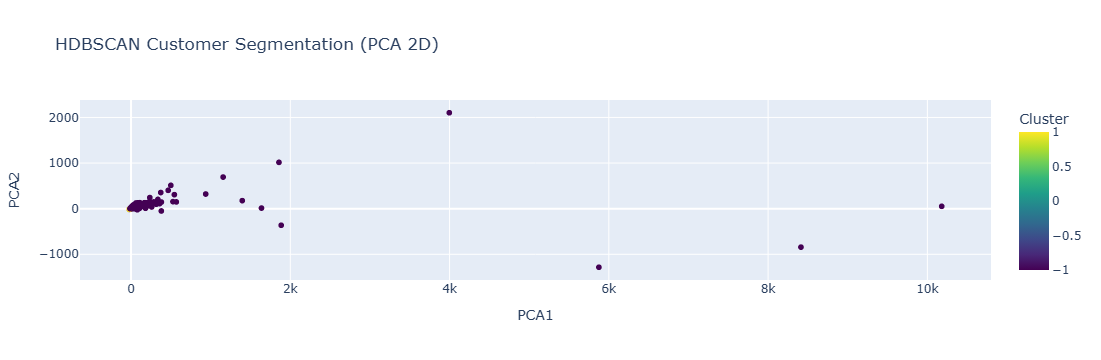

In [22]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2)
reduced = pca.fit_transform(X_scaled)
scaled_data['PCA1'], scaled_data['PCA2'] = reduced[:, 0], reduced[:, 1]

fig = px.scatter(
    scaled_data,
    x='PCA1',
    y='PCA2',
    color='Cluster',
    title='HDBSCAN Customer Segmentation (PCA 2D)',
    color_continuous_scale='Viridis'
)
fig.show()


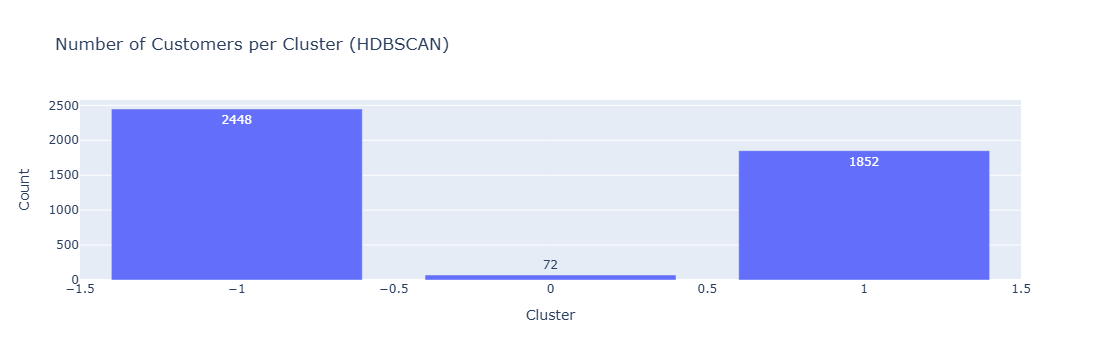

In [23]:
cluster_counts = scaled_data['Cluster'].value_counts().reset_index()
cluster_counts.columns = ['Cluster', 'Count']

fig = px.bar(
    cluster_counts,
    x='Cluster',
    y='Count',
    text='Count',
    title='Number of Customers per Cluster (HDBSCAN)'
)
fig.show()


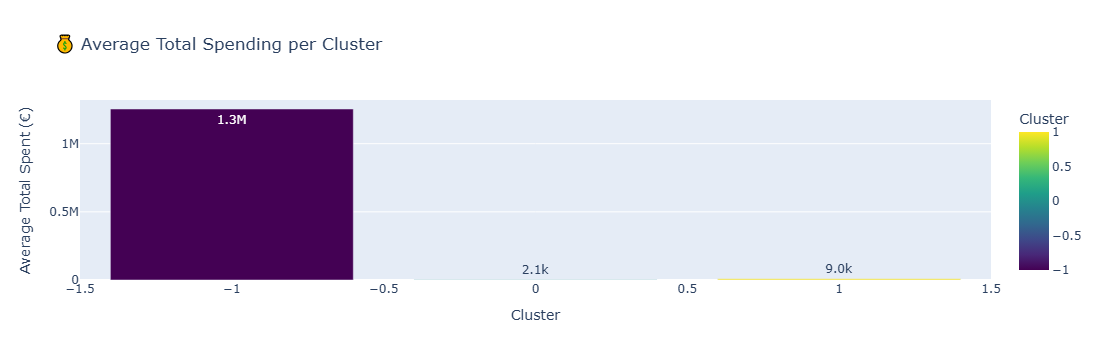

In [24]:
import plotly.express as px

cluster_spend = real_data.groupby('Cluster')['TotalSpent'].mean().reset_index()

fig = px.bar(
    cluster_spend,
    x='Cluster',
    y='TotalSpent',
    color='Cluster',
    text_auto='.2s',
    title='💰 Average Total Spending per Cluster',
    color_continuous_scale='Viridis'
)
fig.update_layout(xaxis_title='Cluster', yaxis_title='Average Total Spent (€)')
fig.show()


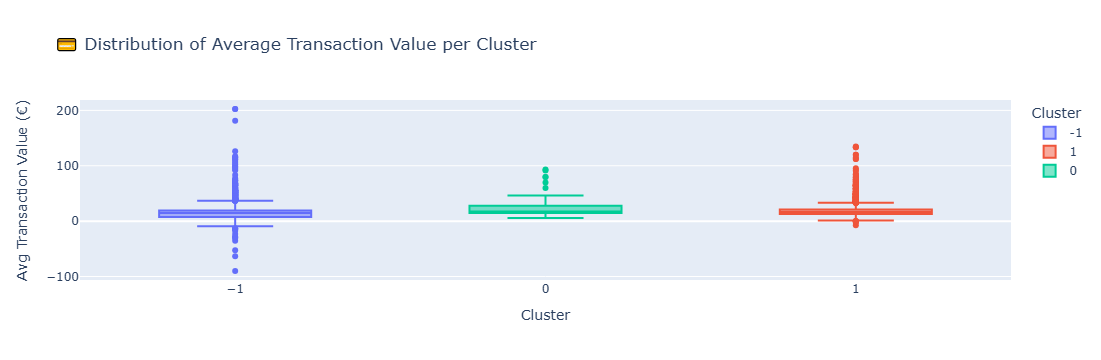

In [25]:
fig = px.box(
    real_data,
    x='Cluster',
    y='AvgTransactionValue',
    color='Cluster',
    title='💳 Distribution of Average Transaction Value per Cluster'
)
fig.update_layout(xaxis_title='Cluster', yaxis_title='Avg Transaction Value (€)')
fig.show()


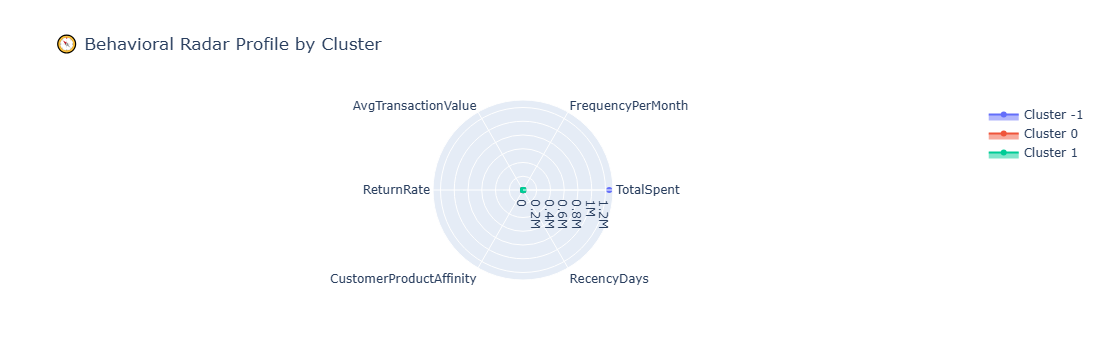

In [27]:
import plotly.graph_objects as go

features_for_radar = [
    'TotalSpent', 'FrequencyPerMonth', 'AvgTransactionValue',
    'ReturnRate', 'CustomerProductAffinity', 'RecencyDays'
]

cluster_means = real_data.groupby('Cluster')[features_for_radar].mean().reset_index()
categories = features_for_radar

fig = go.Figure()

for i, row in cluster_means.iterrows():
    fig.add_trace(go.Scatterpolar(
        r=row[features_for_radar].values,
        theta=categories,
        fill='toself',
        name=f'Cluster {int(row["Cluster"])}'
    ))

fig.update_layout(
    polar=dict(radialaxis=dict(visible=True)),
    title='🧭 Behavioral Radar Profile by Cluster'
)
fig.show()
